# Jev-style escalation model

One shared Qwen3 causal LM provides restricted-option probabilities in fast and reasoning modes. A separate gate decides when reasoning is worth its cost. Run top to bottom. Set `SMOKE_TEST=True` first; completed examples are checkpointed during long prediction and trace stages, so rerun after a disconnect to resume.

The full experiment is compute intensive. Defaults target a Colab T4, with Kaggle paths detected automatically.

In [1]:
# Configuration — all experiment settings live here
import os, json, gc, time, math, random, hashlib, warnings
from pathlib import Path

SMOKE_TEST = False
SEED = 2026
BASE_MODEL = "Qwen/Qwen3-1.7B"
FALLBACK_MODEL = "Qwen/Qwen3-0.6B"
TEACHER = "Qwen/Qwen3-4B"  # Set None to use the base model
MAX_REASON_TOKENS = 256
TRAIN_PER_TASK, VAL_PER_TASK, TEST_PER_TASK = (500, 150, 250)
TRACE_TOTAL = 345
EPOCHS = 2
LR = 2e-4
LORA_R, LORA_ALPHA, LORA_DROPOUT = 16, 32, 0.05
BATCH_SIZE, GRAD_ACCUM = 1, (2 if SMOKE_TEST else 8)
MAX_SEQ_LEN = 1024

ROOT = Path('/scratch/gitanjali.a.ug24/nanbugfix_medium')

for d in ['data','traces','checkpoints','predictions','metrics','plots']:
    (ROOT/d).mkdir(parents=True, exist_ok=True)

print('Output directory:', ROOT.resolve())

print('Output directory:', ROOT.resolve())

Output directory: /scratch/gitanjali.a.ug24/nanbugfix_medium
Output directory: /scratch/gitanjali.a.ug24/nanbugfix_medium


## Setup
Only the specified packages are installed. Restart the runtime after installation if prompted.

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch
from datasets import load_dataset
from transformers import (AutoTokenizer, AutoModelForCausalLM, Trainer, TrainingArguments,
                          DataCollatorForLanguageModeling, set_seed)
from peft import LoraConfig, get_peft_model, PeftModel
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline

set_seed(SEED); random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(SEED)
DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
DTYPE = torch.float16 if DEVICE == 'cuda' else torch.float32
print(torch.__version__, DEVICE, torch.cuda.get_device_name(0) if DEVICE=='cuda' else '')

/home/gitanjali.a.ug24/envs/jev_gpu/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


2.11.0+cu128 cuda NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb


## Data loading and canonicalization
We inspect examples before mapping fields. Dataset ids/configurations follow the specification. Stable hashed content ids support split leakage assertions.

In [3]:
TASKS = ['sentiment','inference','science questions','general knowledge','word math']
DESCRIPTIONS = {
 'sentiment':'Classify the sentiment of the review as positive or negative.',
 'inference':'Determine whether the hypothesis is entailed, contradicted, or neutral given the premise.',
 'science questions':'Answer the grade school science question.',
 'general knowledge':'Answer the multiple-choice exam question.',
 'word math':'Solve the math word problem.'}

def inspect(ds, name):
    print('\n', name, 'splits:', {k:len(v) for k,v in ds.items()})
    print('example:', ds[next(iter(ds))][0])

raw = {}
raw['sentiment'] = load_dataset('stanfordnlp/sst2')
raw['inference'] = load_dataset('facebook/anli')
raw['science questions'] = load_dataset('allenai/ai2_arc', 'ARC-Challenge')
raw['general knowledge'] = load_dataset('cais/mmlu', 'all')
raw['word math'] = load_dataset('deepmind/aqua_rat', 'raw')
for name, ds in raw.items(): inspect(ds, name)


 sentiment splits: {'train': 67349, 'validation': 872, 'test': 1821}
example: {'idx': 0, 'sentence': 'hide new secretions from the parental units ', 'label': 0}

 inference splits: {'train_r1': 16946, 'dev_r1': 1000, 'test_r1': 1000, 'train_r2': 45460, 'dev_r2': 1000, 'test_r2': 1000, 'train_r3': 100459, 'dev_r3': 1200, 'test_r3': 1200}
example: {'uid': '0fd0abfb-659e-4453-b196-c3a64d2d8267', 'premise': 'The Parma trolleybus system (Italian: "Rete filoviaria di Parma" ) forms part of the public transport network of the city and "comune" of Parma, in the region of Emilia-Romagna, northern Italy. In operation since 1953, the system presently comprises four urban routes.', 'hypothesis': 'The trolleybus system has over 2 urban routes', 'label': 0, 'reason': ''}

 science questions splits: {'train': 1119, 'test': 1172, 'validation': 299}
example: {'id': 'Mercury_SC_415702', 'question': 'George wants to warm his hands quickly by rubbing them. Which skin surface will produce the most heat?',

In [4]:
# Dataset-specific field mapping. This cell intentionally prints raw schemas above first.
def norm_text(x): return str(x).strip()
def hash_example(task, q, opts, label):
    return hashlib.sha256((task+'\n'+q+'\n'+'\n'.join(opts)+'\n'+str(label)).encode()).hexdigest()

def letters_to_label(answer, letters):
    a=str(answer).strip().upper().replace('(', '').replace(')', '').replace('.', '')
    if a in letters: return letters.index(a)
    try: return int(a)
    except: return None

def map_sst(row):
    q='Review: '+norm_text(row['sentence']); return q, ['negative','positive'], int(row['label'])
def map_anli(row):
    label=int(row['label']); return 'Premise: '+norm_text(row['premise'])+'\nHypothesis: '+norm_text(row['hypothesis']), ['entailment','neutral','contradiction'], label
def map_arc(row):
    ch=row['choices']; opts=list(map(norm_text,ch['text'])); labs=list(map(str,ch['label']))
    return norm_text(row['question']), opts, labs.index(str(row['answerKey']))
def map_mmlu(row):
    opts=[norm_text(x) for x in row['choices']]; return norm_text(row['question']),opts,int(row['answer'])
def map_aqua(row):
    opts=[norm_text(x) for x in row['options']]; labels=[x.split(')',1)[0].strip(' (') for x in opts]
    opts=[x.split(')',1)[1].strip() if ')' in x else x for x in opts]
    return norm_text(row['question']),opts,letters_to_label(row['correct'],labels)

# Source split allocation: SST validation is partitioned into disjoint val/test pools.
MAP={ 'sentiment':map_sst,'inference':map_anli,'science questions':map_arc,'general knowledge':map_mmlu,'word math':map_aqua}
SOURCES={
 'sentiment':('train','validation','validation'),
 'inference':('train_r1','dev_r1','test_r1'),
 'science questions':('train','validation','test'),
 'general knowledge':('auxiliary_train','dev','test'),
 'word math':('train','validation','test')}

def make_record(task,row):
    q,opts,label=MAP[task](row)
    if not opts or label is None or label<0 or label>=len(opts): return None
    # Deterministic per-example shuffle, preserving answer identity.
    seed=int(hashlib.sha256((str(SEED)+task+q).encode()).hexdigest()[:8],16)
    order=list(range(len(opts))); random.Random(seed).shuffle(order)
    new_label=order.index(label); opts=[opts[i] for i in order]
    return {'id':hash_example(task,q,opts,new_label),'task':task,'question':q,'options':opts,'label':new_label}

def take(ds, n, seed):
    ids=list(range(len(ds))); random.Random(seed).shuffle(ids); return [ds[i] for i in ids[:n]]

DATA={}
for task, ds in raw.items():
    tr,va,te=SOURCES[task]
    if task=='sentiment':
        pool=ds['validation']; indices=list(range(len(pool))); random.Random(SEED).shuffle(indices)
        nv=min(VAL_PER_TASK,len(indices)//2); val_raw=[pool[i] for i in indices[:nv]]; test_raw=[pool[i] for i in indices[nv:nv+min(TEST_PER_TASK,len(indices)-nv)]]
        train_raw=take(ds['train'],TRAIN_PER_TASK,SEED)
    else:
        train_raw=take(ds[tr],TRAIN_PER_TASK,SEED); val_raw=take(ds[va],VAL_PER_TASK,SEED+1); test_raw=take(ds[te],TEST_PER_TASK,SEED+2)
    mapped=lambda rows:[x for x in (make_record(task,r) for r in rows) if x is not None]
    DATA[task]={'train':mapped(train_raw),'val':mapped(val_raw),'test':mapped(test_raw)}
    print(task,{k:len(v) for k,v in DATA[task].items()})

# Leakage guard. Held-out word math is excluded from every training stage.
train_ids={x['id'] for t in TASKS[:-1] for x in DATA[t]['train']}
val_ids={x['id'] for t in TASKS for x in DATA[t]['val']}
test_ids={x['id'] for t in TASKS for x in DATA[t]['test']}
assert not (train_ids & val_ids or train_ids & test_ids), 'Split leakage detected'
assert not any(t=='word math' for t in [x['task'] for task in TASKS[:-1] for x in DATA[task]['train']])
with open(ROOT/'data/splits.json','w') as f: json.dump(DATA,f,indent=2)

sentiment {'train': 500, 'val': 150, 'test': 250}


inference {'train': 500, 'val': 150, 'test': 250}
science questions {'train': 500, 'val': 150, 'test': 250}


general knowledge {'train': 500, 'val': 150, 'test': 250}


word math {'train': 500, 'val': 150, 'test': 250}


## Model and restricted typed readout
Token ids are derived from the actual tokenizer and checked to be single tokens. Fast output is a distribution over only the valid answer letters.

In [5]:
try:
    tokenizer=AutoTokenizer.from_pretrained(BASE_MODEL, trust_remote_code=True)
    MODEL_NAME=BASE_MODEL
except Exception as e:
    print('Primary model load failed; using fallback:',repr(e)); MODEL_NAME=FALLBACK_MODEL
    tokenizer=AutoTokenizer.from_pretrained(MODEL_NAME, trust_remote_code=True)
if tokenizer.pad_token is None: tokenizer.pad_token=tokenizer.eos_token
LETTERS=list('ABCDE')
LETTER_IDS={}
for letter in LETTERS:
    ids=tokenizer.encode(' '+letter, add_special_tokens=False)
    if len(ids)!=1: ids=tokenizer.encode(letter, add_special_tokens=False)
    assert len(ids)==1, f'{letter} does not map to one token: {ids}'
    LETTER_IDS[letter]=ids[0]
print('Readout token ids:',LETTER_IDS)

def prompt_for(ex, reasoning=False):
    body=f"Task: {DESCRIPTIONS[ex['task']]}\nQuestion: {ex['question']}\nOptions:\n"
    body+=''.join(f"{LETTERS[i]}. {opt}\n" for i,opt in enumerate(ex['options']))
    body+='Answer:'
    if reasoning: body+='\nReasoning:'
    return body

def load_model(name=MODEL_NAME, adapter=None):
    m=AutoModelForCausalLM.from_pretrained(name, torch_dtype=DTYPE, device_map='auto' if DEVICE=='cuda' else None, trust_remote_code=True)
    if adapter: m=PeftModel.from_pretrained(m, adapter)
    m.eval(); return m

def get_logits_hidden(model, prompt):
    x=tokenizer(prompt,return_tensors='pt').to(model.device)
    with torch.no_grad(): out=model(**x, output_hidden_states=True, use_cache=True)
    return out.logits[0,-1],out.hidden_states[-1][0,-1],x,out.past_key_values

def restricted_probs(logits,n,temp=1.0):
    ids=torch.tensor([LETTER_IDS[x] for x in LETTERS[:n]],device=logits.device)
    p=torch.softmax(logits[ids].float()/temp,dim=-1).cpu().numpy()
    assert np.isclose(p.sum(),1,atol=1e-5)
    return p

Readout token ids: {'A': 362, 'B': 425, 'C': 356, 'D': 422, 'E': 468}


## Shared inference functions and stage 0 baseline
Reasoning generation uses the prompt KV cache and emits only an internal scratch trace; returned answers remain distributions.

In [6]:
def infer_one(model, ex, reasoning=False, max_new=MAX_REASON_TOKENS):
    start=time.time(); p=prompt_for(ex,reasoning=False)
    logits,h,inputs,prompt_past=get_logits_hidden(model,p); fast=restricted_probs(logits,len(ex['options']))
    if not reasoning:
        return {'probs':fast.tolist(),'hidden':h.float().cpu().tolist(),'generated_tokens':0,'seconds':time.time()-start}
    # Cache already contains the prompt. Feed Reasoning: and continue generation.
    rp=prompt_for(ex,reasoning=True); rinputs=tokenizer(rp,return_tensors='pt').to(model.device)
    with torch.no_grad():
        gen=model.generate(**rinputs, max_new_tokens=max_new, do_sample=False, use_cache=True,
                           pad_token_id=tokenizer.pad_token_id, eos_token_id=tokenizer.eos_token_id)
    seq=gen[0]; text=tokenizer.decode(seq[rinputs['input_ids'].shape[1]:],skip_special_tokens=True)
    # Force the typed suffix after the generated scratch. Use cache by forwarding full suffix continuation.
    suffix='\nFinal answer:'
    all_text=rp+text+suffix; enc=tokenizer(all_text,return_tensors='pt').to(model.device)
    with torch.no_grad(): rout=model(**enc, output_hidden_states=True)
    probs=restricted_probs(rout.logits[0,-1],len(ex['options']))
    return {'probs':probs.tolist(),'hidden':rout.hidden_states[-1][0,-1].float().cpu().tolist(),
            'generated_tokens':int(seq.shape[0]-rinputs['input_ids'].shape[1]),'seconds':time.time()-start,'scratch':text}


def save_json_atomic(rows, path, max_retries=5):
    import os
    import time

    path = Path(path)

    for attempt in range(max_retries):
        tmp = path.with_name(
            path.name + f".{os.getpid()}.{attempt}.tmp"
        )

        try:
            with open(tmp, "w", encoding="utf-8") as f:
                json.dump(rows, f)
                f.flush()
                os.fsync(f.fileno())

            tmp.replace(path)
            return

        except OSError as e:
            print(f"Checkpoint attempt {attempt + 1} failed: {e}")

            try:
                tmp.unlink(missing_ok=True)
            except OSError:
                pass

            if attempt == max_retries - 1:
                raise

            time.sleep(2 * (attempt + 1))


def run_predictions(model, examples, path, modes=("fast", "reasoning")):
    path = Path(path)
    existing = json.load(open(path)) if path.exists() else []

    done = {r["id"] for r in existing}
    out = list(existing)

    print(f"Resuming: {len(done)} / {len(examples)} predictions already saved")

    for i, ex in enumerate(examples):
        if ex["id"] in done:
            continue

        row = {
            "id": ex["id"],
            "task": ex["task"],
            "label": ex["label"],
            "n_options": len(ex["options"])
        }

        for mode in modes:
            z = infer_one(model, ex, mode == "reasoning")
            row[mode] = z

        out.append(row)
        done.add(ex["id"])

        if len(done) % 5 == 0 or len(done) == len(examples):
            save_json_atomic(out, path)
            print("Saved predictions", len(done), "/", len(examples))

    byid = {r["id"]: r for r in out}
    out = [
        byid[x["id"]]
        for x in examples
        if x["id"] in byid
    ]

    save_json_atomic(out, path)
    print("Completed:", len(out), "/", len(examples))

    return out

BASE=load_model()
for split in ['val','test']:
    exs=[x for t in TASKS for x in DATA[t][split]]
    run_predictions(BASE,exs,ROOT/f'predictions/stage0_{split}.json')
del BASE; gc.collect(); torch.cuda.empty_cache() if DEVICE=='cuda' else None

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/311 [00:04<22:59,  4.45s/it]

Loading weights:   1%|          | 2/311 [00:06<14:30,  2.82s/it]

Loading weights:  47%|████▋     | 145/311 [00:06<00:03, 41.51it/s]

Loading weights:  64%|██████▍   | 200/311 [00:07<00:02, 42.70it/s]

... (7 outputs left out)

Resuming: 749 / 750 predictions already saved


Completed: 750 / 750


Resuming: 1250 / 1250 predictions already saved


Completed: 1250 / 1250


## Stage 1: teacher traces
Training-only examples from the four seen tasks are sampled. Teacher outputs are rejection sampled by final answer. All prompts, traces and labels are saved.

In [7]:
trace_path=ROOT/'traces/train_traces.json'
if not trace_path.exists() or len(json.load(open(trace_path))) < TRACE_TOTAL:
    teacher_name=TEACHER or MODEL_NAME
    teacher=load_model(teacher_name)
    eligible=[x for t in TASKS[:-1] for x in DATA[t]['train']]
    random.Random(SEED).shuffle(eligible); eligible=eligible[:TRACE_TOTAL]
    traces=json.load(open(trace_path)) if trace_path.exists() else []
    done={t['id'] for t in traces}
    for ex in eligible:
        if ex['id'] in done: continue
        ask=prompt_for(ex)+'\nReason in under 150 words. End with exactly: Final answer: X'
        enc=tokenizer(ask,return_tensors='pt').to(teacher.device)
        with torch.no_grad(): gen=teacher.generate(**enc,max_new_tokens=220,do_sample=False,use_cache=True)
        completion=tokenizer.decode(gen[0,enc['input_ids'].shape[1]:],skip_special_tokens=True)
        import re
        matches=re.findall(r'Final answer:\s*([ABCDE])',completion,re.I)
        if matches and LETTERS.index(matches[-1].upper())==ex['label']:
            reasoning=completion[:completion.lower().rfind('final answer:')].strip()
            traces.append({'id':ex['id'],'task':ex['task'],'prompt':prompt_for(ex),'reasoning':reasoning,'answer':LETTERS[ex['label']]})
        done.add(ex['id'])
        if len(done)%5==0 or len(done)==len(eligible):
            tmp=trace_path.with_suffix('.json.tmp')
            with open(tmp,'w') as f: json.dump(traces,f,indent=2)
            tmp.replace(trace_path)
            print('saved traces',len(done),'/',len(eligible),'accepted',len(traces))
    print('Trace keep rates:',{t:sum(z['task']==t for z in traces)/max(sum(x['task']==t for x in eligible),1) for t in TASKS[:-1]})
    del teacher; gc.collect(); torch.cuda.empty_cache() if DEVICE=='cuda' else None
else: traces=json.load(open(trace_path))

## Stage 2: LoRA fine-tuning
A single shared adapter is trained on direct answer examples and accepted reasoning traces. Prompt text is masked from reasoning LM loss. The restricted answer loss supervises the option token at the answer position. Training uses gradient accumulation and fp16 on GPU.

In [8]:
# Configure all attention/MLP linear projection modules using the model's discovered module names.
base=load_model()
linear_names=set()
for name,module in base.named_modules():
    if isinstance(module,torch.nn.Linear):
        leaf=name.split('.')[-1]
        if any(k in leaf.lower() for k in ['q_proj','k_proj','v_proj','o_proj','gate_proj','up_proj','down_proj']): linear_names.add(leaf)
assert linear_names, 'No transformer projection layers discovered'
print('LoRA targets:',sorted(linear_names))
peft_cfg=LoraConfig(r=LORA_R,lora_alpha=LORA_ALPHA,lora_dropout=LORA_DROPOUT,target_modules=sorted(linear_names),task_type='CAUSAL_LM')
model=get_peft_model(base,peft_cfg); model.print_trainable_parameters()

trace_ids={t['id'] for t in traces}
assert trace_ids.isdisjoint(val_ids|test_ids), 'Validation/test trace leakage'
train_examples=[x for t in TASKS[:-1] for x in DATA[t]['train']]
class MixDataset(torch.utils.data.Dataset):
    def __init__(self, rows): self.rows=rows
    def __len__(self): return len(self.rows)
    def __getitem__(self,i):
        r=self.rows[i]; ex=r['ex']; prompt=prompt_for(ex)
        if r.get('trace'):
            text=prompt+'\nReasoning: '+r['trace']['reasoning']+'\nFinal answer:'
        else: text=prompt
        tok=tokenizer(text, truncation=True,max_length=MAX_SEQ_LEN,return_tensors='pt')
        ids=tok['input_ids'][0]; labels=ids.clone()
        if r.get('trace'):
            pids=tokenizer(prompt+'\nReasoning:',add_special_tokens=False)['input_ids']
            labels[:min(len(pids),len(labels))]=-100
        else:
            labels[:]=-100
        return {'input_ids':ids,'attention_mask':tok['attention_mask'][0],'labels':labels,'readout_pos':len(ids)-1,'n_options':len(ex['options']),'answer':ex['label']}
rows=[{'ex':x} for x in train_examples]+[{'ex':next(y for y in train_examples if y['id']==t['id']),'trace':t} for t in traces if t['id'] in train_ids]
random.Random(SEED).shuffle(rows)
class Collator:
    def __call__(self, items):
        # right padding for training
        mx=max(len(z['input_ids']) for z in items); ids=[]; masks=[]; labs=[]
        for z in items:
            n=mx-len(z['input_ids']); ids.append(torch.cat([z['input_ids'],torch.full((n,),tokenizer.pad_token_id)])); masks.append(torch.cat([z['attention_mask'],torch.zeros(n,dtype=torch.long)])); labs.append(torch.cat([z['labels'],torch.full((n,),-100)]))
        return {'input_ids':torch.stack(ids),'attention_mask':torch.stack(masks),'labels':torch.stack(labs),'readout_pos':torch.tensor([z['readout_pos'] for z in items]),'n_options':torch.tensor([z['n_options'] for z in items]),'answer':torch.tensor([z['answer'] for z in items])}
train_ds=MixDataset(rows)
ckpt=ROOT/'checkpoints/lora_adapter'
if not (ckpt/'adapter_config.json').exists():
    args=TrainingArguments(output_dir=str(ROOT/'checkpoints/trainer'),num_train_epochs=EPOCHS,learning_rate=LR,per_device_train_batch_size=BATCH_SIZE,gradient_accumulation_steps=GRAD_ACCUM,fp16=(DEVICE=='cuda'),logging_steps=10,save_strategy='steps',save_steps=100,save_total_limit=2,report_to='none',max_grad_norm=1.0,remove_unused_columns=False)
    
    class ReadoutTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
            labels = inputs.pop('labels')
            pos = inputs.pop('readout_pos')
            nopts = inputs.pop('n_options')
            answer = inputs.pop('answer')
            # Does this batch contain any valid reasoning tokens?
            has_lm = (labels != -100).any().item()
            # Only calculate reasoning loss if valid targets exist
            out = model(
                **inputs,
                labels=labels if has_lm else None
            )
            ids = torch.tensor(
                [LETTER_IDS[x] for x in LETTERS[:int(nopts.max())]],
                device=out.logits.device
            )
            z = out.logits[
                torch.arange(len(pos), device=out.logits.device), pos
            ][:, ids].float()
            z = z.masked_fill(
                torch.arange(z.shape[1], device=z.device)[None, :] >= nopts.to(z.device)[:, None],
                -1e4
            )
            # Always calculate answer loss
            answer_loss = torch.nn.functional.cross_entropy(
                z, answer.to(z.device)
            )
            # Use zero reasoning loss for direct-only batches
            lm_loss = out.loss if has_lm else z.sum() * 0.0
            loss = lm_loss + answer_loss
            return (loss, out) if return_outputs else loss
    trainer=ReadoutTrainer(model=model,args=args,train_dataset=train_ds,data_collator=Collator())
    trainer.train(); model.save_pretrained(ckpt); tokenizer.save_pretrained(ckpt)
else: print('Adapter exists; loading saved adapter')
del model,base; gc.collect(); torch.cuda.empty_cache() if DEVICE=='cuda' else None

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/311 [00:00<01:13,  4.24it/s]

Loading weights:  26%|██▌       | 81/311 [00:00<00:00, 291.55it/s]

Loading weights:  43%|████▎     | 133/311 [00:00<00:00, 364.63it/s]

Loading weights:  60%|██████    | 188/311 [00:00<00:00, 419.70it/s]

Loading weights:  76%|███████▌  | 237/311 [00:00<00:00, 433.17it/s]

Loading weights:  92%|█████████▏| 285/311 [00:00<00:00, 445.29it/s]

Loading weights: 100%|██████████| 311/311 [00:00<00:00, 387.79it/s]

LoRA targets: ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']


trainable params: 17,432,576 || all params: 1,738,007,552 || trainable%: 1.0030
Adapter exists; loading saved adapter


## Calibration, gate fitting, and evaluation helpers
Temperatures and gate parameters are fit using seen-task validation data only. The held-out word-math task is excluded from gate fitting.

In [9]:
def nll(probs,labels):
    return float(-np.mean([np.log(max(p[y],1e-12)) for p,y in zip(probs,labels)]))
def fit_temperature(rows, mode):
    ps=np.array([r[mode]['probs'] for r in rows],dtype=object); ys=[r['label'] for r in rows]
    def loss(logt):
        t=np.exp(logt); return nll([np.asarray(p)**(1/t)/np.sum(np.asarray(p)**(1/t)) for p in ps],ys)
    from scipy.optimize import minimize_scalar
    return float(np.exp(minimize_scalar(loss,bounds=(-3,3),method='bounded').x))
def calib_metrics(probs,labels,bins=10):
    conf=np.array([max(p) for p in probs]); pred=np.array([int(np.argmax(p)) for p in probs]); ok=(pred==np.array(labels))
    ece=0.0
    for lo in np.linspace(0,1,bins+1)[:-1]:
        hi=lo+1/bins; ix=(conf>=lo)&(conf<(hi if hi<1 else hi+1e-8))
        if ix.any(): ece+=ix.mean()*abs(ok[ix].mean()-conf[ix].mean())
    one=np.zeros((len(labels),max(map(len,probs))))
    for i,y in enumerate(labels): one[i,y]=1
    pp=np.zeros_like(one)
    for i,p in enumerate(probs): pp[i,:len(p)]=p
    return {'accuracy':float(ok.mean()),'ece':float(ece),'nll':nll(probs,labels),'brier':float(np.mean(np.sum((pp-one)**2,axis=1)))}
def features(row):
    p=np.array(row['fast']['probs']); s=np.sort(p); ent=float(-(p*np.log(np.maximum(p,1e-12))).sum())
    h=np.array(row['fast']['hidden'],dtype=np.float32)
    return np.r_[s[-1],s[-1]-s[-2],ent,row['n_options'],h]

def calibrated(rows, temps):
    for r in rows:
        for mode in ['fast','reasoning']:
            p=np.array(r[mode]['probs'],dtype=float); p=p**(1/temps[mode]); r[mode]['calibrated_probs']=(p/p.sum()).tolist()
    return rows

# Load tuned model and run validation predictions (saved separately).
tuned=load_model(adapter=ckpt)
val_examples=[x for t in TASKS for x in DATA[t]['val']]
val_rows=run_predictions(tuned,val_examples,ROOT/'predictions/stage2_val.json')
seen_val=[r for r in val_rows if r['task'] in TASKS[:-1]]
temps={m:fit_temperature(seen_val,m) for m in ['fast','reasoning']}
json.dump(temps,open(ROOT/'metrics/temperatures.json','w'),indent=2); print('Temperatures:',temps)
val_rows=calibrated(val_rows,temps); json.dump(val_rows,open(ROOT/'predictions/stage3_val_calibrated.json','w'))
# Labels whether reasoning rescues fast. Logistic gate split is internal validation holdout.
X=np.stack([features(r) for r in seen_val]); y=np.array([int(np.argmax(r['fast']['calibrated_probs'])!=r['label'] and np.argmax(r['reasoning']['calibrated_probs'])==r['label']) for r in seen_val])
if len(y)>=4 and len(np.unique(y))>1:
    Xtr,Xte,ytr,yte=train_test_split(X,y,test_size=0.25,random_state=SEED,stratify=y if min(np.bincount(y))>=2 else None)
else: Xtr,Xte,ytr,yte=X,X,y,y
gate=make_pipeline(StandardScaler(),LogisticRegression(max_iter=1000,class_weight='balanced',random_state=SEED)).fit(Xtr,ytr)
import pickle
with open(ROOT/'metrics/learned_gate.pkl','wb') as f: pickle.dump(gate,f)
print('Gate rescue holdout accuracy:',float(gate.score(Xte,yte)) if len(yte) else None)

Loading weights:   0%|          | 0/311 [00:00<?, ?it/s]

Loading weights:   0%|          | 1/311 [00:00<01:22,  3.75it/s]

Loading weights:  26%|██▌       | 81/311 [00:00<00:00, 269.12it/s]

Loading weights:  41%|████      | 126/311 [00:00<00:00, 324.20it/s]

Loading weights:  58%|█████▊    | 180/311 [00:00<00:00, 391.06it/s]

Loading weights:  76%|███████▌  | 235/311 [00:00<00:00, 431.13it/s]

... (101 outputs left out)

Saved predictions 740 / 750


Saved predictions 745 / 750


Completed: 750 / 750
Temperatures: {'fast': 3.578094200767216, 'reasoning': 5.699827931126172}


Gate rescue holdout accuracy: 0.8866666666666667


## Stage 5: test predictions and metrics
All metrics and plots below are computed from saved predictions. This cell performs the one test inference pass and caches the result.

In [10]:
test_examples=[x for t in TASKS for x in DATA[t]['test']]
test_rows=run_predictions(tuned,test_examples,ROOT/'predictions/stage5_test.json')
test_rows=calibrated(test_rows,temps); json.dump(test_rows,open(ROOT/'predictions/stage5_test_calibrated.json','w'))
del tuned; gc.collect(); torch.cuda.empty_cache() if DEVICE=='cuda' else None

def metric_for(rows,mode,prob_key='calibrated_probs'):
    ps=[r[mode][prob_key] for r in rows]; ys=[r['label'] for r in rows]; return calib_metrics(ps,ys)

def run_gate(rows,selector):
    out=[]
    for r in rows:
        fast=np.array(r['fast']['calibrated_probs']); reason=np.array(r['reasoning']['calibrated_probs'])
        escalate=bool(selector(r))
        p=reason if escalate else fast
        out.append((r,escalate,p))
    return out

def summarize_gate(items):
    ps=[p.tolist() for _,_,p in items]; ys=[r['label'] for r,_,_ in items]
    m=calib_metrics(ps,ys); m['escalation_rate']=float(np.mean([e for _,e,_ in items]))
    m['avg_tokens']=float(np.mean([r['reasoning']['generated_tokens'] if e else 0 for r,e,_ in items]))
    m['avg_seconds']=float(np.mean([r['reasoning']['seconds'] if e else r['fast']['seconds'] for r,e,_ in items]))
    return m

def eval_group(rows):
    result={'n':len(rows)}
    for mode in ['fast','reasoning']: result[mode]=metric_for(rows,mode)
    result['confident_wrong_fast_share']=float(np.mean([np.argmax(r['fast']['calibrated_probs'])!=r['label'] for r in rows if max(r['fast']['calibrated_probs'])>=.95])) if any(max(r['fast']['calibrated_probs'])>=.95 for r in rows) else None
    result['confident_fast_count']=sum(max(r['fast']['calibrated_probs'])>=.95 for r in rows)
    return result

summary={t:eval_group([r for r in test_rows if r['task']==t]) for t in TASKS}
summary['overall']=eval_group(test_rows)
json.dump(summary,open(ROOT/'metrics/results.json','w'),indent=2)
print(json.dumps(summary,indent=2))

Resuming: 0 / 1250 predictions already saved


Saved predictions 5 / 1250


Saved predictions 10 / 1250


Saved predictions 15 / 1250


Saved predictions 20 / 1250


Saved predictions 25 / 1250


... (245 outputs left out)

Saved predictions 1245 / 1250


Saved predictions 1250 / 1250


Completed: 1250 / 1250


{
  "sentiment": {
    "n": 250,
    "fast": {
      "accuracy": 0.932,
      "ece": 0.04201360571253963,
      "nll": 0.2149521712605528,
      "brier": 0.11321335524455019
    },
    "reasoning": {
      "accuracy": 0.944,
      "ece": 0.047179205982988526,
      "nll": 0.22356617094511536,
      "brier": 0.10903074741651397
    },
    "confident_wrong_fast_share": 0.028985507246376812,
    "confident_fast_count": 69
  },
  "inference": {
    "n": 250,
    "fast": {
      "accuracy": 0.556,
      "ece": 0.16764319213737117,
      "nll": 1.0008617155393695,
      "brier": 0.6014125324784667
    },
    "reasoning": {
      "accuracy": 0.68,
      "ece": 0.0871909610045461,
      "nll": 0.8633565318362829,
      "brier": 0.49484329323405946
    },
    "confident_wrong_fast_share": null,
    "confident_fast_count": 0
  },
  "science questions": {
    "n": 250,
    "fast": {
      "accuracy": 0.832,
      "ece": 0.08713013987381196,
      "nll": 0.5124302001878793,
      "brier": 0.250485

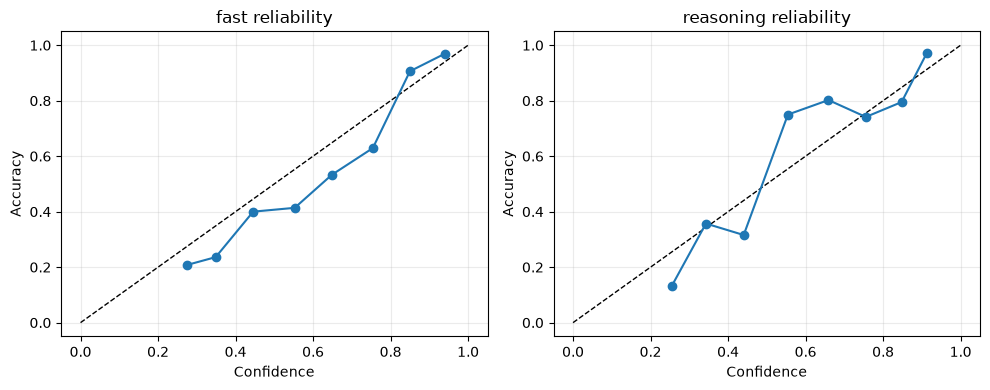

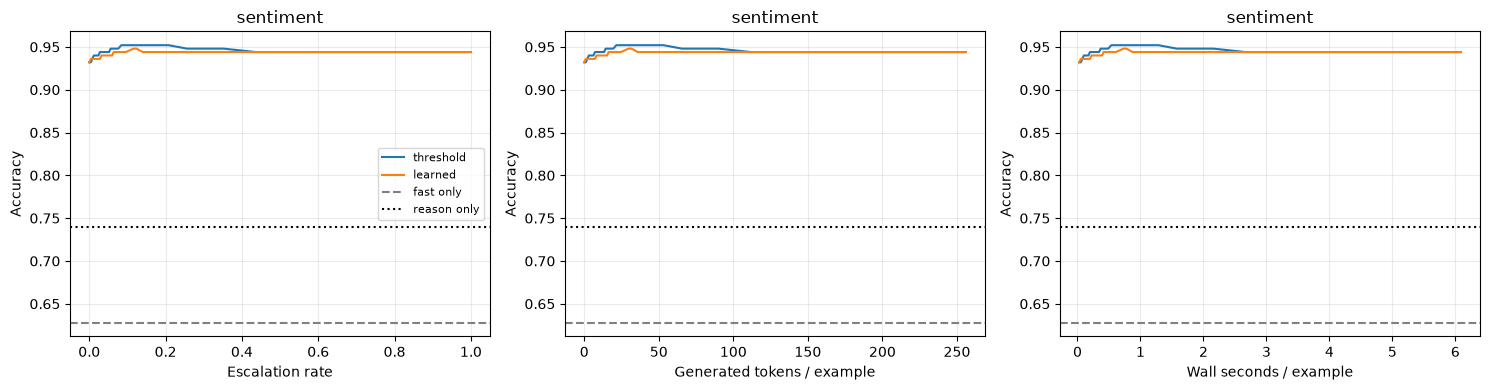

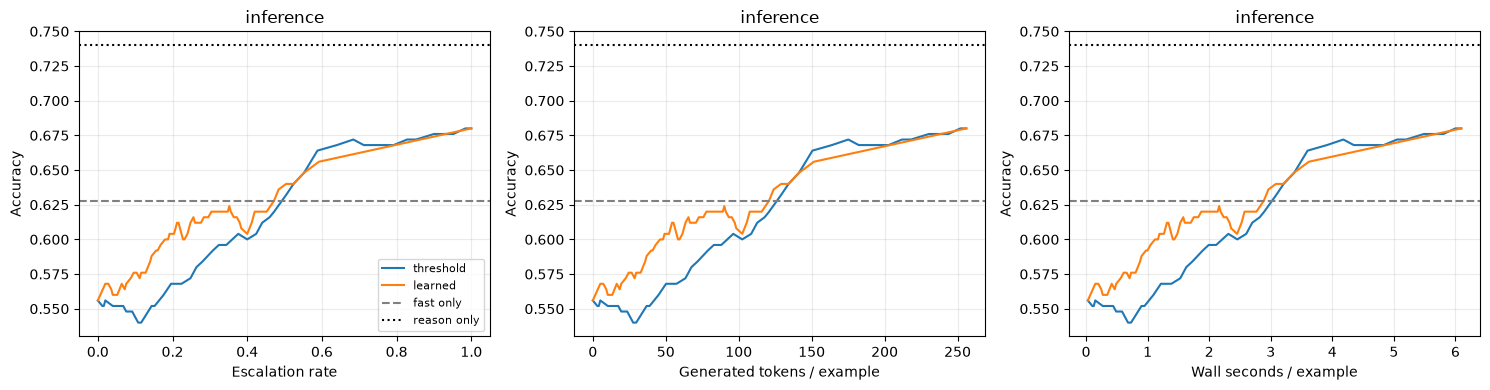

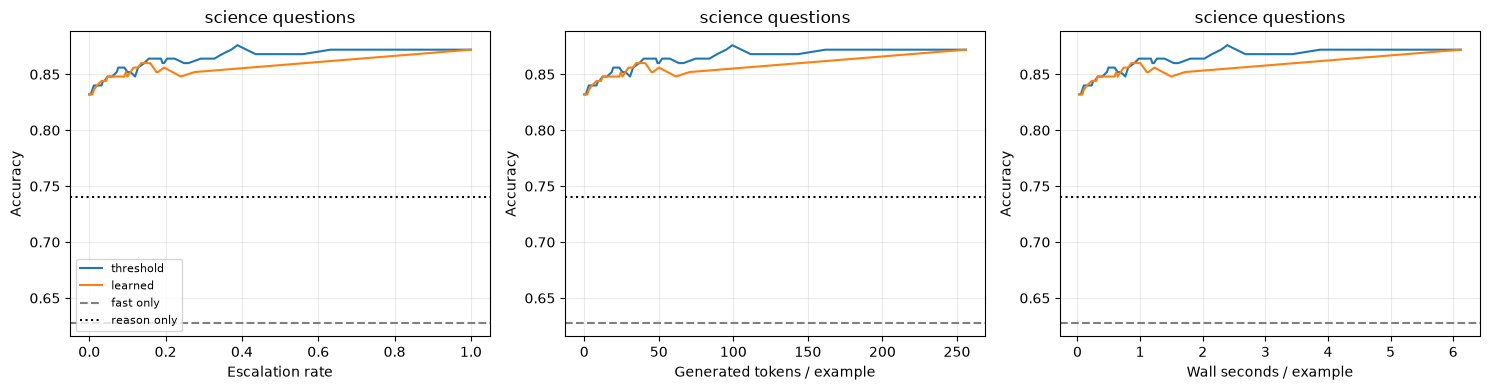

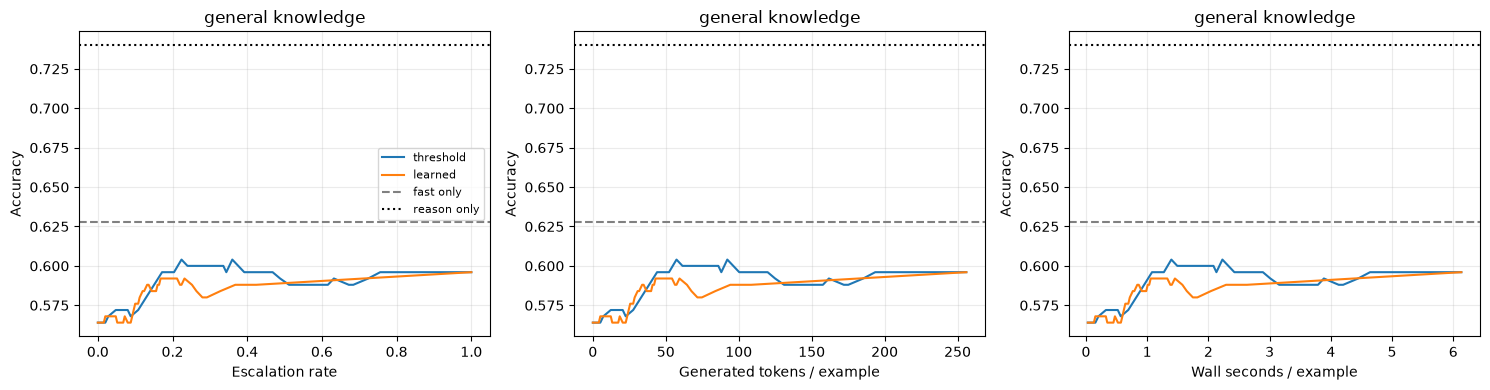

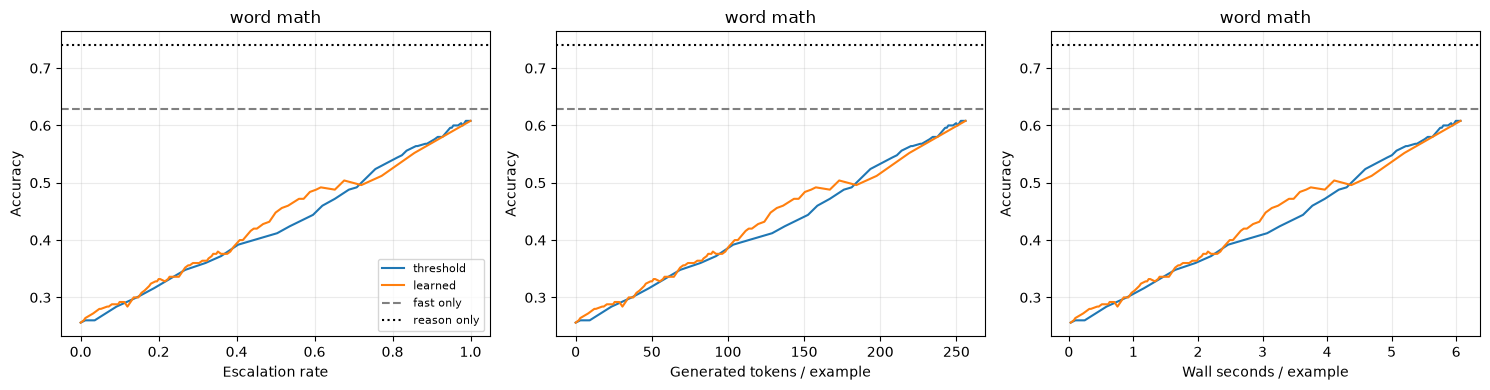

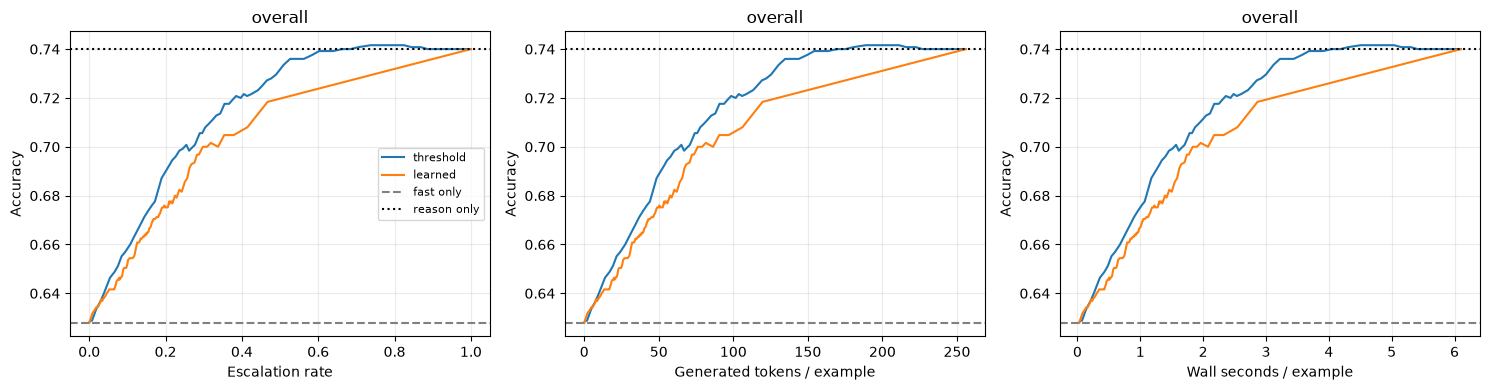

In [11]:
# Reliability plots, plus sweep curves and baselines, using stored predictions only.
def reliability(ax,rows,mode):
    ps=[r[mode]['calibrated_probs'] for r in rows]; ys=[r['label'] for r in rows]
    conf=np.array([max(p) for p in ps]); acc=np.array([int(np.argmax(p)==y) for p,y in zip(ps,ys)])
    xs=[]; vals=[]
    for lo in np.linspace(0,1,11)[:-1]:
        ix=(conf>=lo)&(conf<lo+.1+1e-9)
        if ix.any(): xs.append(conf[ix].mean()); vals.append(acc[ix].mean())
    ax.plot([0,1],[0,1],'k--',lw=1); ax.plot(xs,vals,'o-'); ax.set(xlabel='Confidence',ylabel='Accuracy',title=f'{mode} reliability'); ax.grid(True,alpha=.25)

fig,axs=plt.subplots(1,2,figsize=(10,4))
reliability(axs[0],test_rows,'fast'); reliability(axs[1],test_rows,'reasoning'); fig.tight_layout(); fig.savefig(ROOT/'plots/reliability.png',dpi=160); plt.show()

def sweep(rows):
    # threshold: escalate when confidence is less than threshold
    out=[]; conf=np.array([max(r['fast']['calibrated_probs']) for r in rows]);
    gate_score=gate.predict_proba(np.stack([features(r) for r in rows]))[:,1]
    for th in np.linspace(0,1,101):
        for name,score in [('threshold',1-conf),('learned',gate_score)]:
            score_map={r['id']:float(score[i]) for i,r in enumerate(rows)}
            items=run_gate(rows,lambda r,sm=score_map,tt=th: sm[r['id']]>=tt)
            out.append({'threshold':float(th),'gate':name,**summarize_gate(items)})
    # exact endpoints and random baseline at matching rates
    return out

curves={}
for task in TASKS+['overall']:
    group=[r for r in test_rows if task=='overall' or r['task']==task]
    curves[task]=sweep(group)
json.dump(curves,open(ROOT/'metrics/gate_sweeps.json','w'),indent=2)
for task,items in curves.items():
    fig,axs=plt.subplots(1,3,figsize=(15,4))
    for gate_name in ['threshold','learned']:
        z=[x for x in items if x['gate']==gate_name]
        axs[0].plot([x['escalation_rate'] for x in z],[x['accuracy'] for x in z],label=gate_name)
        axs[1].plot([x['avg_tokens'] for x in z],[x['accuracy'] for x in z],label=gate_name)
        axs[2].plot([x['avg_seconds'] for x in z],[x['accuracy'] for x in z],label=gate_name)
    fast=metric_for(group,'fast')['accuracy']; reason=metric_for(group,'reasoning')['accuracy']
    for ax,xlabel in zip(axs,['Escalation rate','Generated tokens / example','Wall seconds / example']):
        ax.axhline(fast,color='gray',ls='--',label='fast only'); ax.axhline(reason,color='black',ls=':',label='reason only'); ax.set(xlabel=xlabel,ylabel='Accuracy',title=task); ax.grid(True,alpha=.25)
    axs[0].legend(fontsize=8); fig.tight_layout(); fig.savefig(ROOT/f'plots/gate_{task.replace(" ","_")}.png',dpi=150); plt.show()

## Headline escalation requirements and final report
The sweep chooses thresholds on the validation set in principle; test curves are descriptive. Do not use them to tune. Curves are sorted over all thresholds; escalation fraction endpoints are explicitly included.

In [12]:
def endpoint_items(rows, frac):
    # deterministic confidence-ranked threshold policy at a desired rate
    n=round(frac*len(rows)); order=sorted(range(len(rows)),key=lambda i:max(rows[i]['fast']['calibrated_probs']))
    chosen=set(order[:n]); return run_gate(rows,lambda r: rows.index(r) in chosen)

def required_rates(rows):
    always=metric_for(rows,'reasoning')['accuracy']; ans={}
    for gap in [.01,.03]:
        target=always-gap; found=None
        for f in np.linspace(0,1,101):
            m=summarize_gate(endpoint_items(rows,f))
            if m['accuracy']>=target: found=m['escalation_rate']; break
        ans[f'within_{int(gap*100)}_point_rate']=found
    return ans
headline={t:required_rates([r for r in test_rows if r['task']==t]) for t in TASKS}
headline['overall']=required_rates(test_rows)
json.dump(headline,open(ROOT/'metrics/headline_escalation_rates.json','w'),indent=2)

# compact final table
table=[]
for task in TASKS+['overall']:
    group=[r for r in test_rows if task=='overall' or r['task']==task]
    row={'task':task,'n':len(group)}
    for mode in ['fast','reasoning']:
        m=metric_for(group,mode); row.update({f'{mode}_{k}':m[k] for k in ['accuracy','ece','nll','brier']})
    row['confident_wrong_share']=summary[task]['confident_wrong_fast_share']
    row.update(headline[task]); table.append(row)
final_df=pd.DataFrame(table); display(final_df.round(4))
final_df.to_csv(ROOT/'metrics/final_table.csv',index=False)
print('Saved outputs under',ROOT.resolve())
print('Interpretation: compare fast and reasoning endpoints with each gate curve. A curve that reaches the reasoning endpoint at low escalation indicates useful selective escalation; flat or lower curves indicate little value. Inspect per-task results and confident-wrong share, including held-out word math, before drawing conclusions.')

,task,n,fast_accuracy,fast_ece,fast_nll,fast_brier,reasoning_accuracy,reasoning_ece,reasoning_nll,reasoning_brier,confident_wrong_share,within_1_point_rate,within_3_point_rate
0,sentiment,250,0.932,0.0420,0.2150,0.1132,0.944,0.0472,0.2236,0.1090,0.029,0.008,0.0000
1,inference,250,0.556,0.1676,1.0009,0.6014,0.680,0.0872,0.8634,0.4948,NaN,0.648,0.5600
2,science questions,250,0.832,0.0871,0.5124,0.2505,0.872,0.1304,0.5436,0.2446,NaN,0.160,0.0400
3,general knowledge,250,0.564,0.0967,1.0777,0.5729,0.596,0.1309,1.1445,0.6068,NaN,0.152,0.0320
4,word math,250,0.256,0.1277,1.6631,0.8193,0.608,0.1819,1.0345,0.4892,NaN,0.960,0.9120
5,overall,1250,0.628,0.0830,0.8938,0.4715,0.740,0.0558,0.7619,0.3889,0.029,0.500,0.3296


Saved outputs under /scratch/gitanjali.a.ug24/nanbugfix_medium
Interpretation: compare fast and reasoning endpoints with each gate curve. A curve that reaches the reasoning endpoint at low escalation indicates useful selective escalation; flat or lower curves indicate little value. Inspect per-task results and confident-wrong share, including held-out word math, before drawing conclusions.


In [13]:
print("Experiment directory:", ROOT)
print("Adapter path:", ROOT / 'checkpoints/lora_adapter')
print("Adapter already exists:", (ROOT / 'checkpoints/lora_adapter/adapter_config.json').exists())
print("Trainer path:", ROOT / 'checkpoints/trainer')

Experiment directory: /scratch/gitanjali.a.ug24/nanbugfix_medium
Adapter path: /scratch/gitanjali.a.ug24/nanbugfix_medium/checkpoints/lora_adapter
Adapter already exists: True
Trainer path: /scratch/gitanjali.a.ug24/nanbugfix_medium/checkpoints/trainer
